In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load final cleaned dataset
df_eda = pd.read_csv("Caco2_Papp_20449_single_fragment_dataset.csv")

print("Rows:", df_eda.shape[0])
print("Columns:", df_eda.shape[1])

print("\nColumns:")
print(df_eda.columns.tolist())

print("\nMissing values:")
print(df_eda.isnull().sum())

print("\nDuplicate canonical SMILES:")
print(df_eda["canonical_smiles"].duplicated().sum())

Rows: 20449
Columns: 15

Columns:
['canonical_smiles', 'n_measurements', 'n_assays', 'min_papp', 'max_papp', 'median_papp', 'mean_papp', 'log10_range', 'log10_median_papp', 'mean_median_ratio', 'mol', 'rdkit_canonical_smiles', 'n_fragments', 'parent_mol', 'parent_smiles']

Missing values:
canonical_smiles          0
n_measurements            0
n_assays                  0
min_papp                  0
max_papp                  0
median_papp               0
mean_papp                 0
log10_range               0
log10_median_papp         0
mean_median_ratio         0
mol                       0
rdkit_canonical_smiles    0
n_fragments               0
parent_mol                0
parent_smiles             0
dtype: int64

Duplicate canonical SMILES:
0


# Papp Distribution 

1. Raw median Papp
2. log₁₀(median Papp)

In [2]:
# Summary statistics
print("=== Median Papp ===")
print(df_eda["median_papp"].describe())

print("\n=== Log10 Median Papp ===")
print(df_eda["log10_median_papp"].describe())

=== Median Papp ===
count    20449.000000
mean        44.175566
std        331.251523
min          0.000100
25%          2.400000
50%          9.600000
75%         23.000000
max      27839.450000
Name: median_papp, dtype: float64

=== Log10 Median Papp ===
count    20449.000000
mean         0.852952
std          0.820542
min         -4.000000
25%          0.380211
50%          0.982271
75%          1.361728
max          4.444661
Name: log10_median_papp, dtype: float64


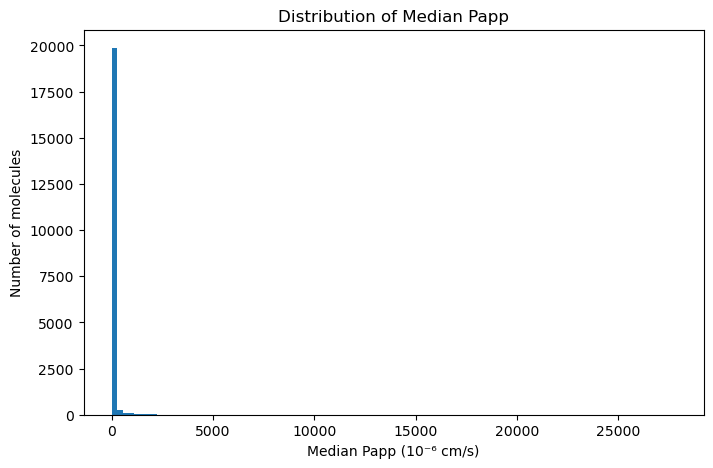

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(df_eda["median_papp"], bins=100)
ax.set_xlabel("Median Papp (10⁻⁶ cm/s)")
ax.set_ylabel("Number of molecules")
ax.set_title("Distribution of Median Papp")

plt.show()

- Papp distribution
- The raw median Papp distribution is extremely right-skewed:
- Median = 9.6 × 10⁻⁶ cm/s
- Q1 = 2.4 × 10⁻⁶ cm/s
- Q3 = 23.0 × 10⁻⁶ cm/s
- Maximum = 27,839.45 × 10⁻⁶ cm/s
- Mean = 44.18, substantially above the median.

The histogram makes this particularly clear: most molecules are concentrated at relatively low Papp values, while a small number extend far into the high-Papp tail.

- let's examine how many measurements each molecule has, because this is particularly relevant to the reliability of our molecule-level median Papp.

In [4]:
print(df_eda["n_measurements"].value_counts().sort_index())

n_measurements
1      16035
2       3665
3        313
4        273
5         30
6         31
7         13
8         22
9          4
10         8
11         5
12         3
13         3
14         3
15         1
16         2
17         1
19         1
20         1
22         2
24         1
25         3
26         2
28         1
29         3
30         2
34         2
36         1
37         1
39         1
40         1
41         1
45         1
47         2
58         1
60         1
65         1
71         1
75         1
83         1
87         1
88         1
109        1
110        1
115        1
Name: count, dtype: int64


In [5]:
print(df_eda["n_measurements"].describe())

count    20449.000000
mean         1.373221
std          2.378046
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max        115.000000
Name: n_measurements, dtype: float64


# let's examine experimental variability among the molecules with repeated measurements.

In [6]:
repeated = df_eda[df_eda["n_measurements"] > 1].copy()

print("Repeated-measurement molecules:", len(repeated))

print("\nLog10 range:")
print(repeated["log10_range"].describe())

Repeated-measurement molecules: 4414

Log10 range:
count    4414.000000
mean        0.574508
std         0.602525
min         0.000000
25%         0.105262
50%         0.355529
75%         0.890115
max         4.623249
Name: log10_range, dtype: float64


- 20,449 molecules remain after the single-fragment filtering.
- 4,414 molecules (~21.6%) have repeated measurements.

For those repeated-measurement molecules:
- Median log10 range = 0.356 log units
- Mean = 0.575
- 75th percentile = 0.890
- Maximum = 4.623 log units

# EDA: relationship between measurement count and variability

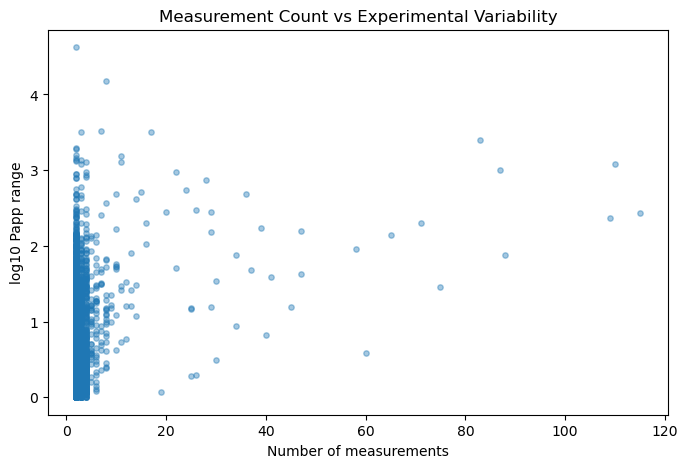

In [7]:
# Repeated measurements vs experimental variability

df_repeat = df_eda[df_eda["n_measurements"] > 1].copy()

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    df_repeat["n_measurements"],
    df_repeat["log10_range"],
    alpha=0.4,
    s=15
)

ax.set_xlabel("Number of measurements")
ax.set_ylabel("log10 Papp range")
ax.set_title("Measurement Count vs Experimental Variability")

plt.show()

# Then calculate the correlation:

In [8]:
df_repeat[["n_measurements", "log10_range"]].corr()

,n_measurements,log10_range
n_measurements,1.00000,0.24481
log10_range,0.24481,1.00000


# variability by measurement count:

In [9]:
df_repeat.groupby("n_measurements")["log10_range"].agg(
    ["count", "median", "mean", "max"]
).head(15)

,count,median,mean,max
n_measurements,,,,
2,3665,0.301030,0.501413,4.623249
3,313,0.712650,0.831377,3.499398
4,273,0.588983,0.778299,3.111431
5,30,0.979926,0.990898,2.123125
6,31,1.041393,0.992336,2.138922
7,13,1.492916,1.382541,3.514149
8,22,1.097207,1.258346,4.176091
9,4,1.201088,1.184913,1.346787
10,8,1.728614,1.691126,2.682102


What we have learned

- 4,414 molecules have repeated measurements.
- For these molecules, the correlation between n_measurements and log10_range is 0.245.
- So there is a weak positive relationship: molecules with more measurements tend to show somewhat greater observed variability, but the relationship is not strong.
With only 2 measurements, median variability is ~0.30 log units.
- It increases for molecules with 5–10+ measurements, but the groups become very small, so we shouldn't overinterpret those values.
- The maximum range of 4.62 log units shows that a small number of molecules have extremely inconsistent reported Papp values.

# EDA: distribution of experimental variability

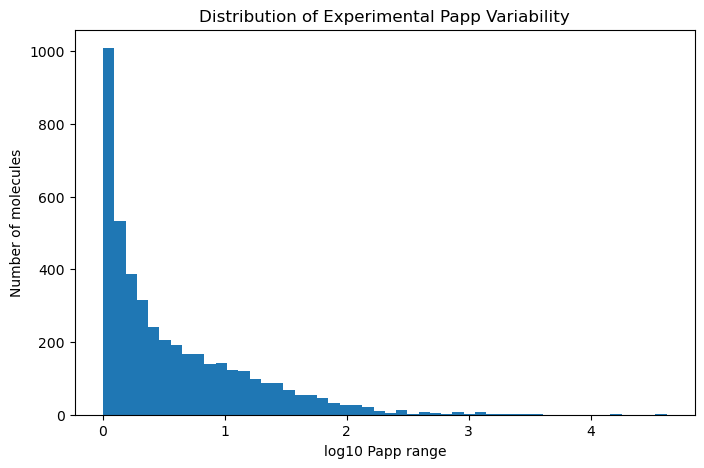

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    df_repeat["log10_range"],
    bins=50
)

ax.set_xlabel("log10 Papp range")
ax.set_ylabel("Number of molecules")
ax.set_title("Distribution of Experimental Papp Variability")

plt.show()

In [11]:
df_repeat["log10_range"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
)

count    4414.000000
mean        0.574508
std         0.602525
min         0.000000
50%         0.355529
75%         0.890115
90%         1.441662
95%         1.763951
99%         2.489979
max         4.623249
Name: log10_range, dtype: float64

So:

- 50% of repeated molecules have a range ≤ 0.356 log units.
- 75% are ≤ 0.890 log units.
- Only 5% exceed 1.764 log units.
- The extreme tail reaches 4.62 log units, indicating a small number of highly inconsistent experimental records.

# EDA: Papp distribution after log transformation

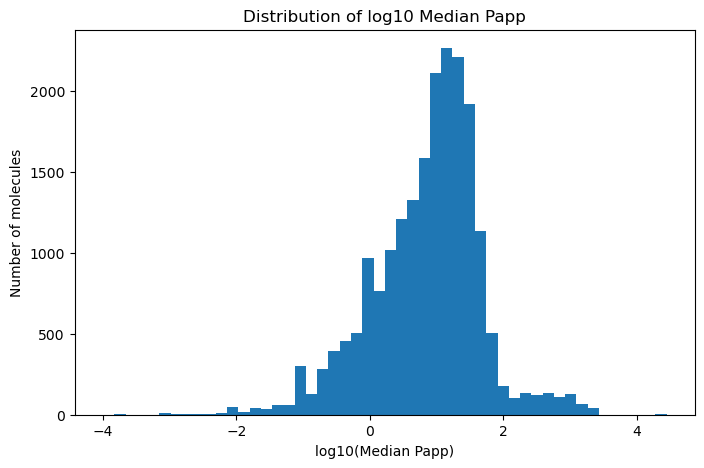

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    df_eda["log10_median_papp"],
    bins=50
)

ax.set_xlabel("log10(Median Papp)")
ax.set_ylabel("Number of molecules")
ax.set_title("Distribution of log10 Median Papp")

plt.show()

In [13]:
df_eda["log10_median_papp"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

count    20449.000000
mean         0.852952
std          0.820542
min         -4.000000
1%          -1.397940
5%          -0.619789
25%          0.380211
50%          0.982271
75%          1.361728
95%          1.915189
99%          2.976386
max          4.444661
Name: log10_median_papp, dtype: float64

# EDA: molecular property distribution
Now we should move from experimental Papp behavior → molecular chemical characteristics.

We'll calculate:
- Molecular weight (MW)
- LogP
- H-bond donors (HBD)
- H-bond acceptors (HBA)
- TPSA
- Rotatable bonds
- Ring count

In [15]:
from rdkit import Chem

df_eda["mol_rdkit"] = df_eda["canonical_smiles"].apply(Chem.MolFromSmiles)

print("Invalid RDKit molecules:",
      df_eda["mol_rdkit"].isna().sum())

Invalid RDKit molecules: 0


In [16]:
from rdkit.Chem import Descriptors, Lipinski

df_eda["MW"] = df_eda["mol_rdkit"].apply(Descriptors.MolWt)
df_eda["LogP"] = df_eda["mol_rdkit"].apply(Descriptors.MolLogP)
df_eda["HBD"] = df_eda["mol_rdkit"].apply(Lipinski.NumHDonors)
df_eda["HBA"] = df_eda["mol_rdkit"].apply(Lipinski.NumHAcceptors)
df_eda["TPSA"] = df_eda["mol_rdkit"].apply(Descriptors.TPSA)
df_eda["RotB"] = df_eda["mol_rdkit"].apply(Lipinski.NumRotatableBonds)
df_eda["RingCount"] = df_eda["mol_rdkit"].apply(Lipinski.RingCount)

In [17]:
df_eda[["MW", "LogP", "HBD", "HBA", "TPSA", "RotB", "RingCount"]].describe()

,MW,LogP,HBD,HBA,TPSA,RotB,RingCount
count,20449.000000,20449.000000,20449.000000,20449.000000,20449.000000,20449.000000,20449.000000
mean,454.833303,3.572056,1.927772,6.047631,96.017212,6.036970,4.111595
std,167.952278,1.593277,2.169580,2.630566,60.299924,4.892157,1.314482
min,93.129000,-17.662680,0.000000,0.000000,0.000000,0.000000,0.000000
25%,373.293000,2.633400,1.000000,4.000000,69.220000,4.000000,3.000000
50%,435.615000,3.556800,2.000000,6.000000,90.540000,5.000000,4.000000
75%,503.994000,4.519000,3.000000,7.000000,112.890000,7.000000,5.000000
max,4278.530000,11.172800,58.000000,52.000000,1583.380000,151.000000,12.000000


# Descriptor distributions

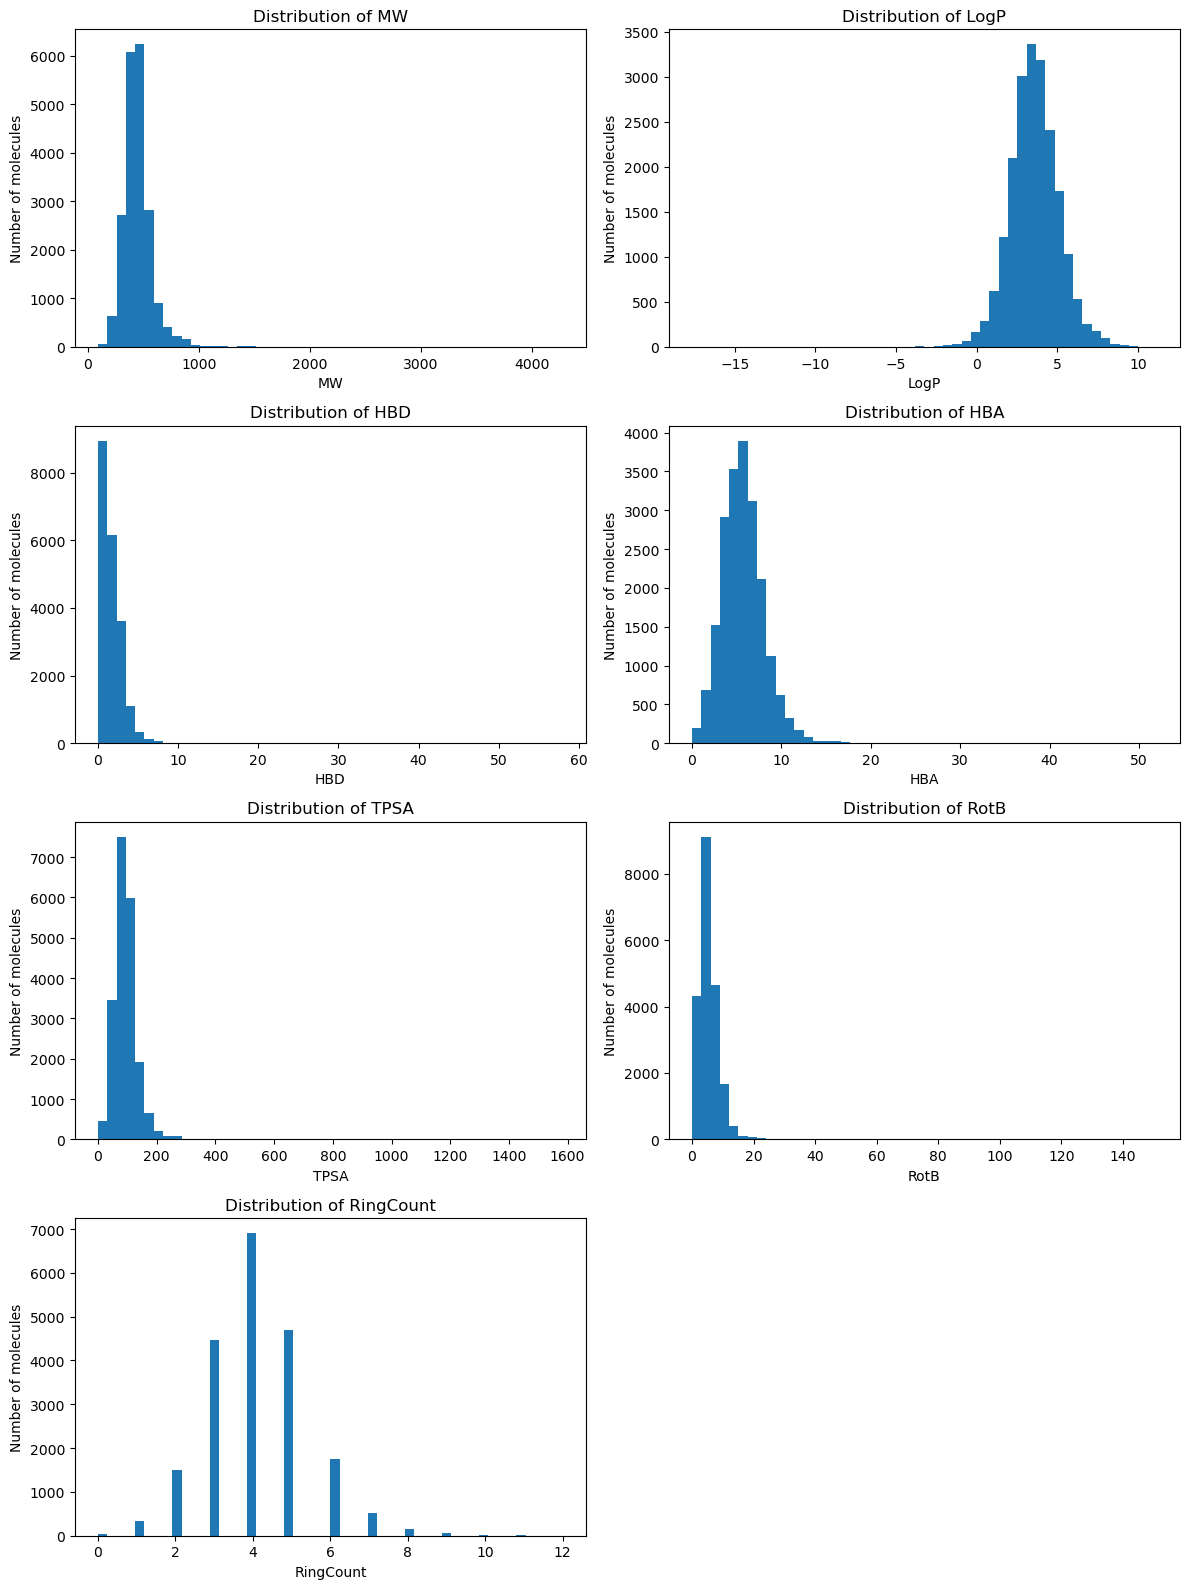

In [18]:
descriptor_cols = [
    "MW", "LogP", "HBD", "HBA",
    "TPSA", "RotB", "RingCount"
]

fig, axes = plt.subplots(4, 2, figsize=(12, 16))

for ax, col in zip(axes.flat, descriptor_cols):
    ax.hist(df_eda[col], bins=50)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of molecules")
    ax.set_title(f"Distribution of {col}")

# Hide unused subplot
axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

# Descriptor–Papp relationship

# calculate Spearman correlations because the distributions are clearly non-normal/skewed.

In [19]:
from scipy.stats import spearmanr

descriptor_cols = [
    "MW", "LogP", "HBD", "HBA",
    "TPSA", "RotB", "RingCount"
]

target = "log10_median_papp"

corr_results = []

for col in descriptor_cols:
    r, p = spearmanr(df_eda[col], df_eda[target])
    corr_results.append({
        "Descriptor": col,
        "Spearman_r": r,
        "p_value": p
    })

corr_df = pd.DataFrame(corr_results)

corr_df.sort_values(
    "Spearman_r",
    key=abs,
    ascending=False
)

,Descriptor,Spearman_r,p_value
4,TPSA,-0.330526,0.000000e+00
2,HBD,-0.314559,0.000000e+00
0,MW,-0.254411,1.735624e-299
3,HBA,-0.203209,1.584418e-189
5,RotB,-0.190911,4.150050e-167
6,RingCount,-0.113347,1.895129e-59
1,LogP,0.057882,1.195265e-16


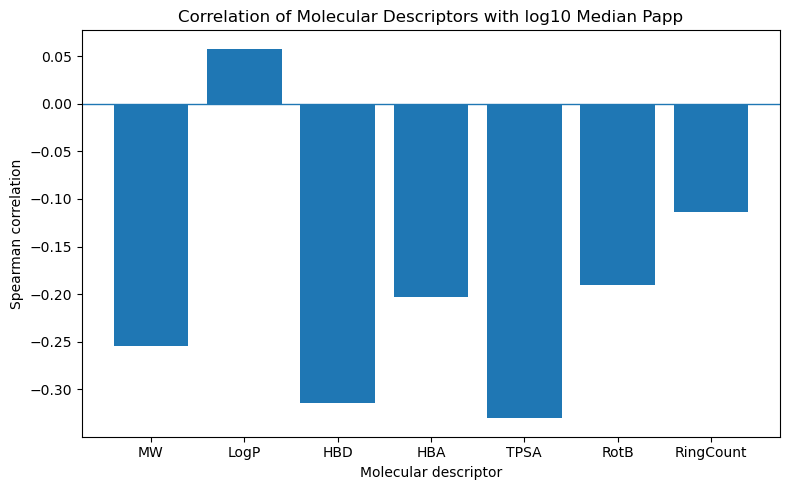

In [20]:
plt.figure(figsize=(8, 5))

plt.bar(
    corr_df["Descriptor"],
    corr_df["Spearman_r"]
)

plt.axhline(0, linewidth=1)
plt.ylabel("Spearman correlation")
plt.xlabel("Molecular descriptor")
plt.title("Correlation of Molecular Descriptors with log10 Median Papp")

plt.tight_layout()
plt.show()

# let's check correlation among the molecular descriptors themselves.
This will tell us whether descriptors such as MW, HBD, HBA, TPSA, etc. contain overlapping information.

In [21]:
descriptor_cols = [
    "MW", "LogP", "HBD", "HBA",
    "TPSA", "RotB", "RingCount"
]

corr_matrix = df_eda[descriptor_cols].corr(method="spearman")

corr_matrix

,MW,LogP,HBD,HBA,TPSA,RotB,RingCount
MW,1.000000,0.392877,0.319488,0.583147,0.602016,0.646888,0.545905
LogP,0.392877,1.000000,-0.082363,-0.129044,-0.186188,0.281586,0.334249
HBD,0.319488,-0.082363,1.000000,0.230765,0.612124,0.313661,-0.006153
HBA,0.583147,-0.129044,0.230765,1.000000,0.740927,0.374363,0.452190
TPSA,0.602016,-0.186188,0.612124,0.740927,1.000000,0.403574,0.239431
RotB,0.646888,0.281586,0.313661,0.374363,0.403574,1.000000,0.117322
RingCount,0.545905,0.334249,-0.006153,0.452190,0.239431,0.117322,1.000000


In [23]:
import seaborn as sns

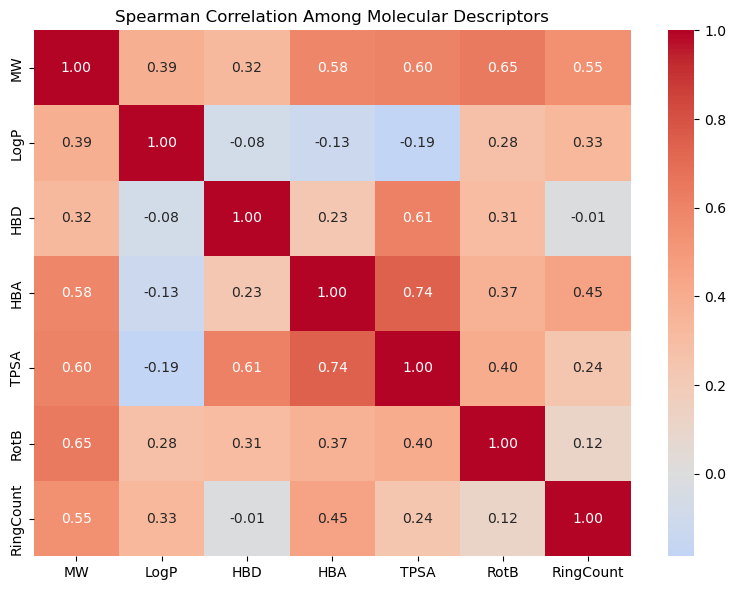

In [24]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Spearman Correlation Among Molecular Descriptors")
plt.tight_layout()
plt.show()

# Papp variability (log10_range) against molecular descriptors

In [25]:
variability_corr = df_repeat[
    ["log10_range"]
].join(
    df_eda[["MW", "LogP", "HBD", "HBA", "TPSA", "RotB", "RingCount"]]
).corr(method="spearman")["log10_range"].drop("log10_range")

variability_corr.sort_values()

LogP         0.010329
RingCount    0.050108
HBA          0.098104
RotB         0.174195
MW           0.175850
TPSA         0.193042
HBD          0.198260
Name: log10_range, dtype: float64

Manuscript figures/tables from this EDA

I would keep the manuscript relatively focused:

- Figure X: Distribution of log10(median Papp)
- Figure X: Distribution of experimental log10_range
- Figure X: Spearman correlation heatmap among molecular descriptors
- Figure X: Descriptor–log10(median Papp) correlations
- Table X: Dataset and descriptor summary statistics